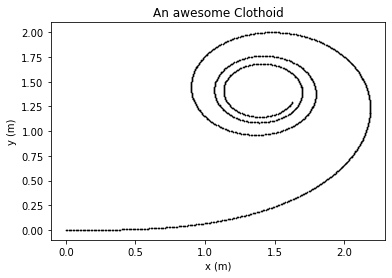

In [1]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

def clothoid_ode_rhs(state, s, kappa0, kappa1):
    x, y, theta = state[0], state[1], state[2]
    return np.array([np.cos(theta), np.sin(theta), kappa0 + kappa1*s])
def eval_clothoid(x0,y0,theta0, kappa0, kappa1, s):
    return odeint(clothoid_ode_rhs, np.array([x0,y0,theta0]), s, (kappa0, kappa1))
x0,y0,theta0 = 0,0,0
L = 10
kappa0, kappa1 = 0, 0.4
s = np.linspace(0, L, 1000)

sol = eval_clothoid(x0, y0, theta0, kappa0, kappa1, s)

xs, ys, thetas = sol[:,0], sol[:,1], sol[:,2] 
plt.scatter(xs, ys, s = 0.5, c = 'k')



plt.xlabel('x (m)');
plt.ylabel('y (m)');
plt.title('An awesome Clothoid');

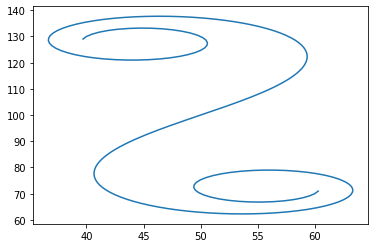

In [2]:
import numpy as np
from math import cos, sin, pi, radians, sqrt
from scipy.special import fresnel
import matplotlib.pyplot as plt


def spiral_interp_centre(distance, x, y, hdg, length, curvEnd):
    '''Interpolate for a spiral centred on the origin'''
    # s doesn't seem to be needed...
    theta = hdg                    # Angle of the start of the curve
    Ltot = length                  # Length of curve
    Rend = 1 / curvEnd             # Radius of curvature at end of spiral

    # Rescale, compute and unscale
    a = 1 / sqrt(2 * Ltot * Rend)  # Scale factor
    distance_scaled = distance * a # Distance along normalised spiral
    deltay_scaled, deltax_scaled = fresnel(distance_scaled)
    deltax = deltax_scaled / a
    deltay = deltay_scaled / a

    # deltax and deltay give coordinates for theta=0
    deltax_rot = deltax * cos(theta) - deltay * sin(theta)
    deltay_rot = deltax * sin(theta) + deltay * cos(theta)

    # Spiral is relative to the starting coordinates
    xcoord = x + deltax_rot
    ycoord = y + deltay_rot

    return xcoord, ycoord

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

# This version
xs = []
ys = []
for n in range(-100, 100+1):
    x, y = spiral_interp_centre(n, 50, 100, radians(56), 40, 1/20.)
    xs.append(x)
    ys.append(y)
ax.plot(xs, ys)

fig.savefig('spiral.png')
plt.show()